# Atelier 1 — Régression : prévoir la prochaine clôture d'Apple

Ce notebook suit les questions du sujet. Le code partagé dans `src/` est commenté
en français. Les résultats enregistrés proviennent d'une exécution complète sur CPU,
avec une graine de 42. La cellule d'entraînement permet de refaire l'expérience.

**Avant de commencer :** suivre l'installation du README et sélectionner le Python
de l'environnement virtuel comme noyau. Dans Colab, cloner le dépôt, entrer dans
son dossier et installer les dépendances ; les commandes sont dans le README.

In [1]:
from pathlib import Path
import os
import sys

# Accepter un lancement depuis la racine du dépôt ou depuis notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir() and (ROOT.parent / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Cloner le dépôt et lancer ce notebook depuis son dossier.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
from IPython.display import display, Image
from src.data import download_data, load_regression, load_classification, NUMERIC, REG_FEATURES
from src.experiments import run_experiment, make_pipeline, parameter_grid
from src.models import MLP

# Le téléchargement est réutilisable et son empreinte est vérifiée à chaque appel.
download_data()

{'prices-split-adjusted.csv': {'kaggle': 'https://www.kaggle.com/datasets/dgawlik/nyse',
  'url': 'https://raw.githubusercontent.com/griffinschwab/NYSE-ML-Project/dfd0e9cf577d6fa2271957ab470c2c81c654bc6b/data/raw/prices-split-adjusted.csv',
  'sha256': '0a8e0505591c8ae8c545d6d9e7bb69735c18568745ef848bf4d01e1afd871ec5'},
 'predictive_maintenance.csv': {'kaggle': 'https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification',
  'url': 'https://raw.githubusercontent.com/beratcmn/machine-maintenance-prediction/9683ce9ccd58e29fb4ef39d116b16416606a2190/data/predictive_maintenance.csv',
  'sha256': 'ba1eb264c69e69258acb2df6991055afc93092b1be436a29d2e6037b0ebd80cc'}}

## 1. Comprendre les données et définir la question

Le jeu NYSE contient plusieurs actions. Nous choisissons **AAPL (Apple)** pour
construire une première expérience claire sur une série homogène.
À la clôture du jour t, nous prédisons la clôture de la prochaine séance.
Les prix du jour t et les statistiques sur les cinq dernières séances sont connus.
Le prix de demain est uniquement la cible : il n'est jamais une entrée.

In [2]:
raw, prepared, parts = load_regression('AAPL')
print(f'Jeu NYSE : {raw.shape[0]:,} lignes, {raw.symbol.nunique()} actions')
display(raw.head())
display(raw.isna().sum().to_frame('Valeurs manquantes'))
display(parts['train'][REG_FEATURES + ['next_close']].describe())

Jeu NYSE : 851,264 lignes, 501 actions


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600


,Valeurs manquantes
date,0
symbol,0
open,0
close,0
low,0
high,0
volume,0


,open,close,low,high,volume,return_1,mean_5,std_5,next_close
count,1228.000000,1228.000000,1228.000000,1228.000000,1.228000e+03,1228.000000,1228.000000,1228.000000,1228.000000
mean,65.355377,65.332742,64.691249,65.944009,1.152242e+08,0.001245,65.193157,0.936974,65.404686
std,20.679123,20.681707,20.526897,20.833982,5.953364e+07,0.016834,20.603681,0.637767,20.713322
min,27.481428,27.435715,27.178572,28.000000,2.289180e+07,-0.123558,27.798286,0.085796,27.435715
25%,48.851786,48.722143,48.255358,49.203214,7.355145e+07,-0.007397,48.669642,0.506543,48.742501
50%,64.353573,64.272144,63.448570,65.022858,1.017012e+08,0.001184,64.182001,0.765311,64.292858
75%,81.281786,81.135714,80.175713,81.825359,1.431838e+08,0.011121,80.981071,1.206553,81.160000
max,117.510002,116.470001,116.029999,117.570000,4.702495e+08,0.088741,115.381999,4.961054,118.629997


## 2. Préparer les données sans utiliser le futur

Nous créons un rendement journalier, une moyenne et un écart-type glissants sur
cinq séances. Les premières lignes sans historique et la dernière ligne sans cible
sont retirées. Le partage est chronologique : environ **70 % / 15 % / 15 %**.
Une ligne est purgée aux frontières pour empêcher le chevauchement des dates cibles.
L'imputation et la standardisation sont apprises sur le train, dans chaque fold.
La cible est aussi standardisée dans `fit`, puis remise en dollars dans `predict`.

In [3]:
display(pd.DataFrame({name: {'lignes': len(frame), 'début': frame.date.min(),
                            'fin': frame.date.max(), 'dernière cible': frame.target_date.max()}
                      for name, frame in parts.items()}).T)
display(prepared[['date', 'close', 'mean_5', 'target_date', 'next_close']].head())
display(make_pipeline('regression'))

,lignes,début,fin,dernière cible
train,1228,2010-01-08 00:00:00,2014-11-21 00:00:00,2014-11-24 00:00:00
validation,263,2014-11-25 00:00:00,2015-12-10 00:00:00,2015-12-11 00:00:00
test,264,2015-12-14 00:00:00,2016-12-29 00:00:00,2016-12-30 00:00:00


,date,close,mean_5,target_date,next_close
4,2010-01-08,30.282858,30.340571,2010-01-11,30.015715
5,2010-01-11,30.015715,30.229143,2010-01-12,29.674286
6,2010-01-12,29.674286,30.038857,2010-01-13,30.092857
7,2010-01-13,30.092857,30.029715,2010-01-14,29.918571
8,2010-01-14,29.918571,29.996857,2010-01-15,29.418571


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('impute', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If 

## 3. Construire un MLP et rechercher les hyperparamètres

Un **MLP** est un réseau de couches entièrement connectées. Les couches cachées
utilisent ReLU. En régression, la sortie est une valeur et la loss est MSE.
En classification, la sortie contient six logits et la loss est l'entropie croisée.

`GridSearchCV` compare neuf configurations : taux d'apprentissage, architecture,
nombre d'époques et optimiseur. Il utilise trois folds, chronologiques avec purge
pour la régression, stratifiés pour la classification. Le score est la RMSE négative
en régression et le F1 macro en classification. Le test n'intervient pas dans ce choix.

In [4]:
# Afficher la grille réellement utilisée, pas seulement la configuration gagnante.
display(parameter_grid(quick=False))

[{'net__lr': [0.001, 0.01],
  'net__optimizer': ['adam'],
  'net__hidden': [(32,), (64, 32)],
  'net__epochs': [40, 80]},
 {'net__lr': [0.01],
  'net__optimizer': ['sgd'],
  'net__hidden': [(64, 32)],
  'net__epochs': [80]}]

## 4. Exécuter l'expérience et comparer les régularisations

Le modèle initial est comparé à Dropout, L2, arrêt anticipé et leur combinaison.
L'arrêt anticipé surveille la loss de validation, avec une patience de dix époques,
et restaure les meilleurs poids. Le modèle final est choisi sur la validation
(RMSE ou F1 macro). Les mesures et courbes de test sont calculées ensuite,
à partir des poids enregistrés à chaque époque ; elles ne guident pas l'entraînement.

Par défaut, nous lisons les résultats déjà produits. Passer `REENTRAINER` à `True`
pour refaire toute la recherche et les entraînements ; cela remplace les résultats
de cette partie dans `results/`. Le mode complet peut prendre quelques minutes.

In [5]:
TASK = 'regression'
REENTRAINER = False
output = ROOT / 'results' / TASK
if REENTRAINER or not (output / 'summary.json').exists():
    run_experiment(TASK, quick=False)

summary = json.loads((output / 'summary.json').read_text())
print('Mode enregistré :', summary['mode'])
print('Configuration CV :', summary['best_parameters_cv'])
print('Modèle choisi sur validation :', summary['selected_on_validation'])
print('Partitions :', summary['split_sizes'])
display(pd.read_csv(output / 'comparison.csv'))

Mode enregistré : full
Configuration CV : {'net__epochs': 80, 'net__hidden': [32], 'net__lr': 0.01, 'net__optimizer': 'adam'}
Modèle choisi sur validation : combined
Partitions : {'train': 1228, 'validation': 263, 'test': 264}


,model,epochs_run,selected_epoch,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,test_mae,test_rmse,test_r2
0,initial,80,80,0.799991,1.116827,0.997090,1.589080,2.071826,0.921568,1.049533,1.466090,0.961712
1,dropout,80,80,0.909444,1.260156,0.996296,2.514104,2.941745,0.841876,1.706156,2.055230,0.924757
2,l2,80,80,0.795418,1.120294,0.997072,1.554515,2.029378,0.924749,1.058447,1.484275,0.960756
3,early_stopping,32,22,0.915562,1.263930,0.996274,1.560962,2.052958,0.922990,1.102757,1.514343,0.959150
4,combined,32,22,0.910586,1.245634,0.996381,1.507763,2.001767,0.926783,1.053309,1.491856,0.960354


In [6]:
# Afficher le réseau retenu : 8 entrées après préparation pour les deux tâches.
params = summary['best_parameters_cv']
display(MLP(inputs=8, outputs=1 if TASK == 'regression' else 6,
            hidden=tuple(params['net__hidden']),
            dropout=.2 if summary['selected_on_validation'] in ['dropout', 'combined'] else 0.))

# Les neuf configurations et leur dispersion entre folds sont consultables.
grid = pd.read_csv(output / 'grid_search.csv')
display(grid[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']]
        .sort_values('rank_test_score'))

MLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

,rank_test_score,mean_test_score,std_test_score,params
5,1,-1.368050,0.096246,"{'net__epochs': 80, 'net__hidden': (32,), 'net..."
1,2,-1.514217,0.154335,"{'net__epochs': 40, 'net__hidden': (32,), 'net..."
7,3,-1.644198,0.358953,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
3,4,-1.691680,0.385490,"{'net__epochs': 40, 'net__hidden': (64, 32), '..."
6,5,-1.930330,0.673748,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
8,6,-2.468288,1.151400,"{'net__epochs': 80, 'net__hidden': (64, 32), '..."
2,7,-3.566853,2.169861,"{'net__epochs': 40, 'net__hidden': (64, 32), '..."
4,8,-4.232372,2.427316,"{'net__epochs': 80, 'net__hidden': (32,), 'net..."
0,9,-10.459890,5.420590,"{'net__epochs': 40, 'net__hidden': (32,), 'net..."


## 5. Visualiser et interpréter

Une loss qui diminue sur le train mais augmente sur validation signale un possible
surapprentissage. Une régularisation n'est pas automatiquement bénéfique : elle
peut aussi empêcher le réseau d'apprendre suffisamment.

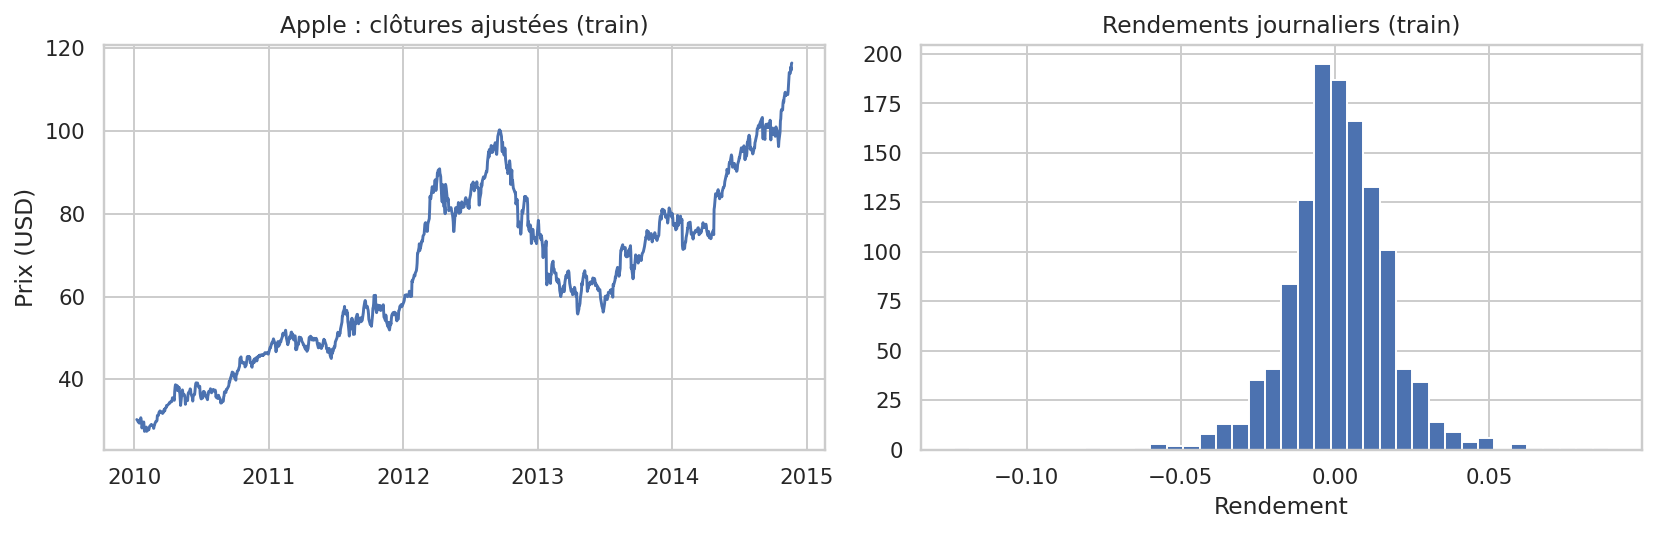

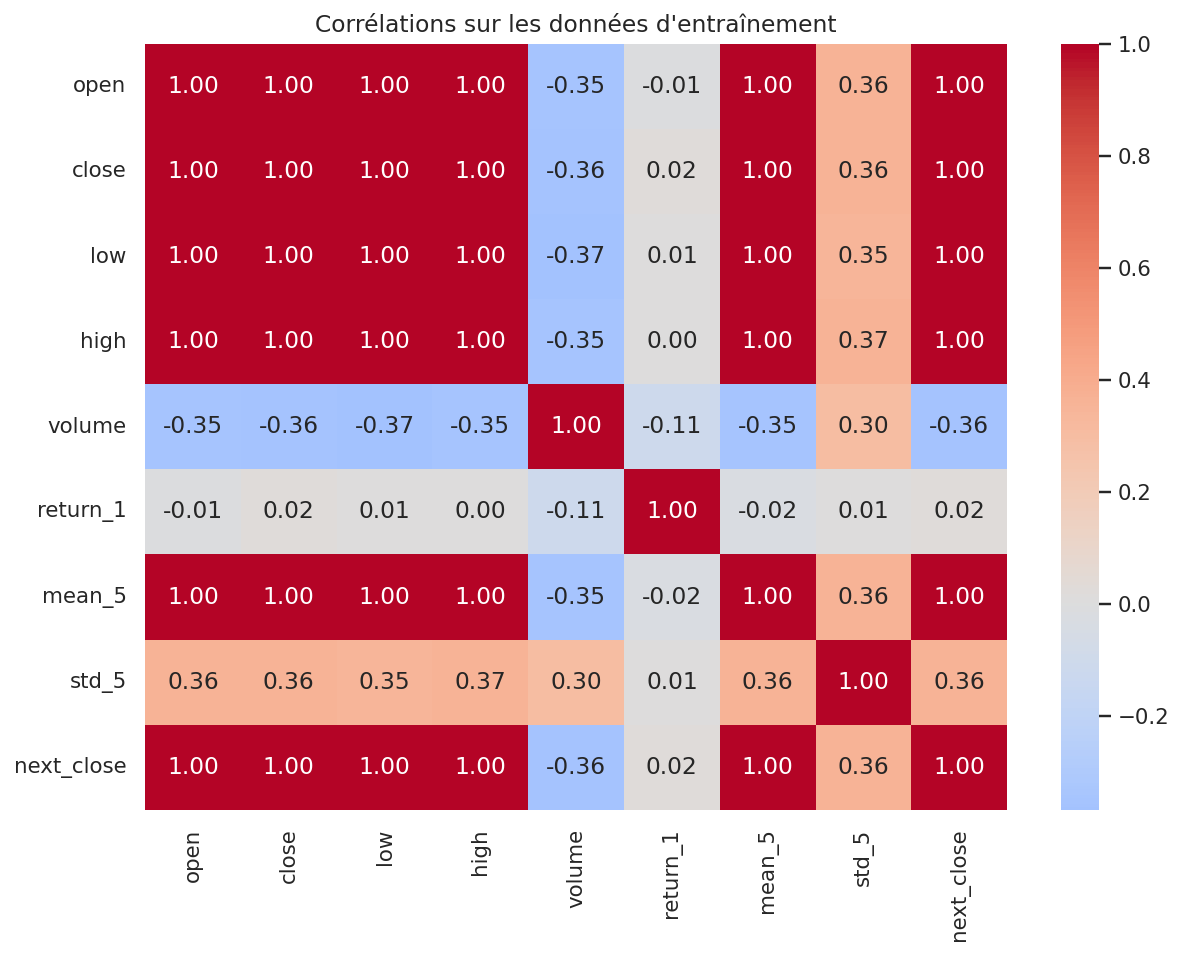

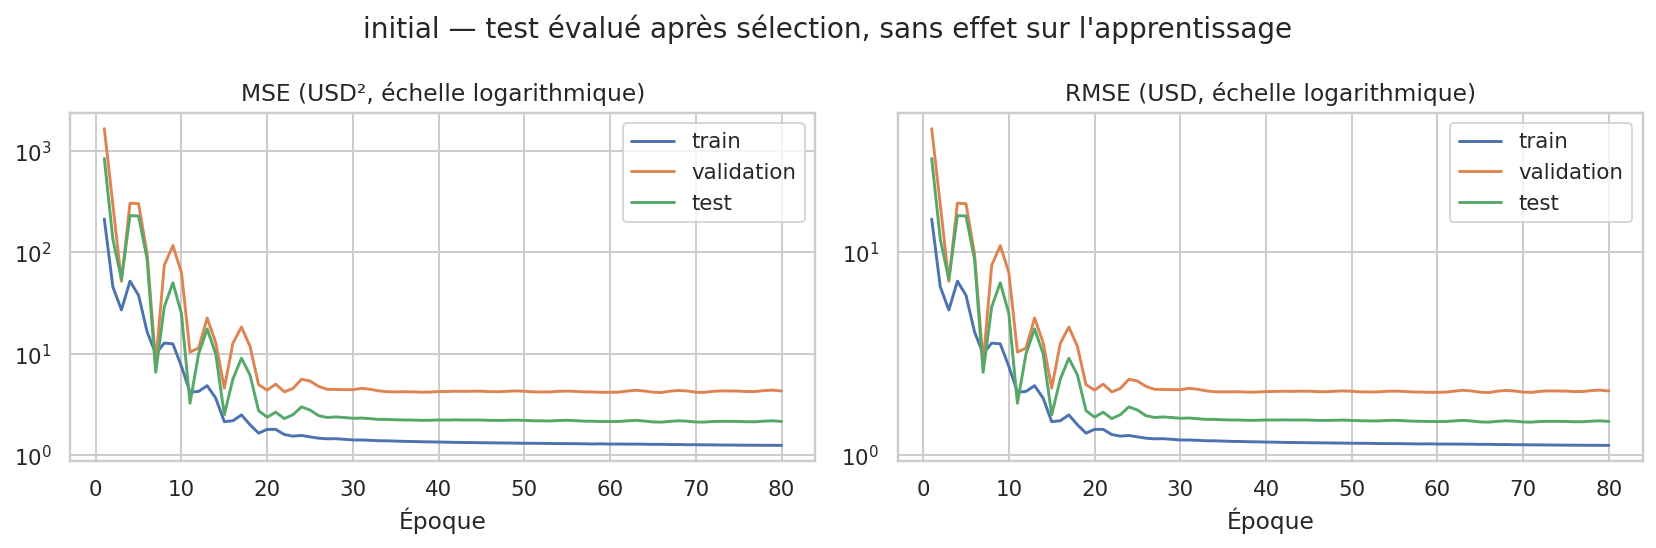

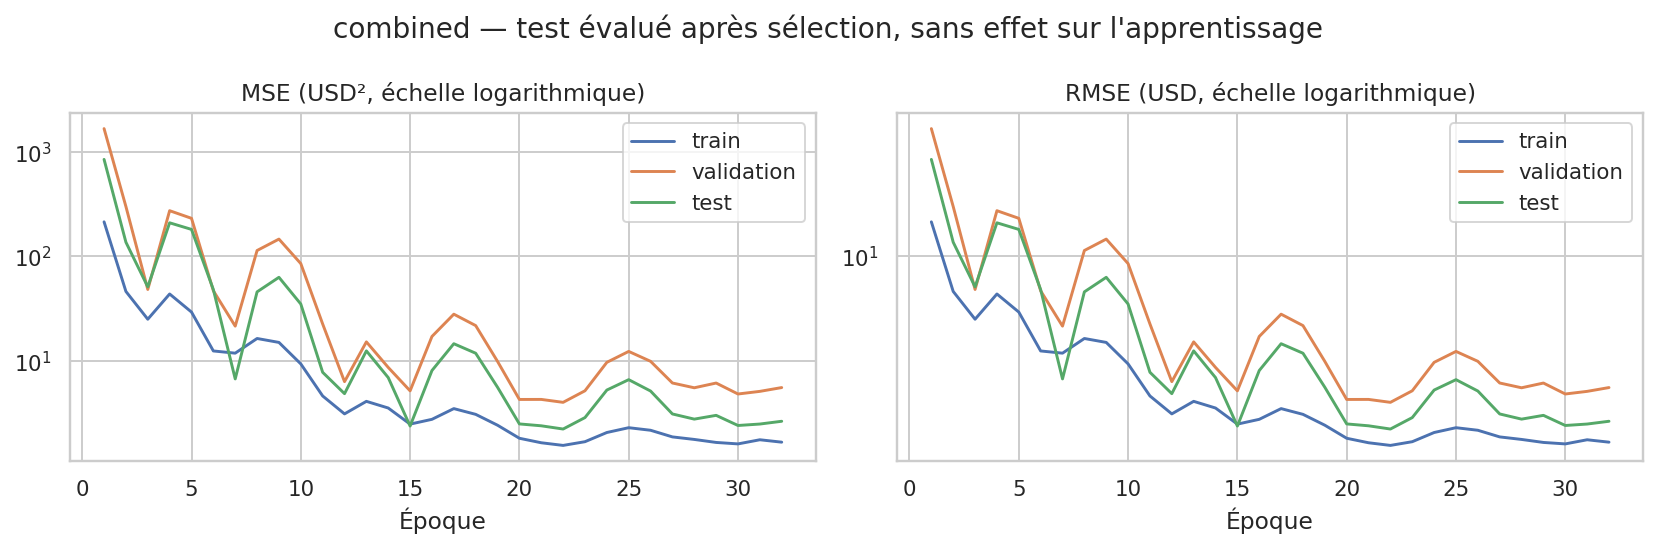

In [7]:
display(Image(filename=str(output / 'eda.png')))
display(Image(filename=str(output / 'correlations.png')))
display(Image(filename=str(output / 'curves_initial.png')))
display(Image(filename=str(output / ('curves_' + summary['selected_on_validation'] + '.png'))))

### Pourquoi la RMSE remplace l'accuracy

L'accuracy compte des catégories correctement prédites ; elle n'a pas de sens
pour un prix continu. Nous traçons donc **MSE / époques et RMSE / époques**, et
rapportons aussi MAE et R². Une petite RMSE/MAE est préférable ; un grand R²
ne prouve pas à lui seul une capacité à prévoir les variations de cours.

Nous comparons au modèle de **persistance** : « demain aura le même cours qu'aujourd'hui ».
Il constitue une référence exigeante. Consulter le README pour l'interprétation
des mesures de l'exécution enregistrée, sans modifier le choix sur la base du test.

,mae,rmse,r2
train,0.780101,1.122816,0.997059
validation,1.491635,1.959241,0.929861
test,1.064848,1.506509,0.959572


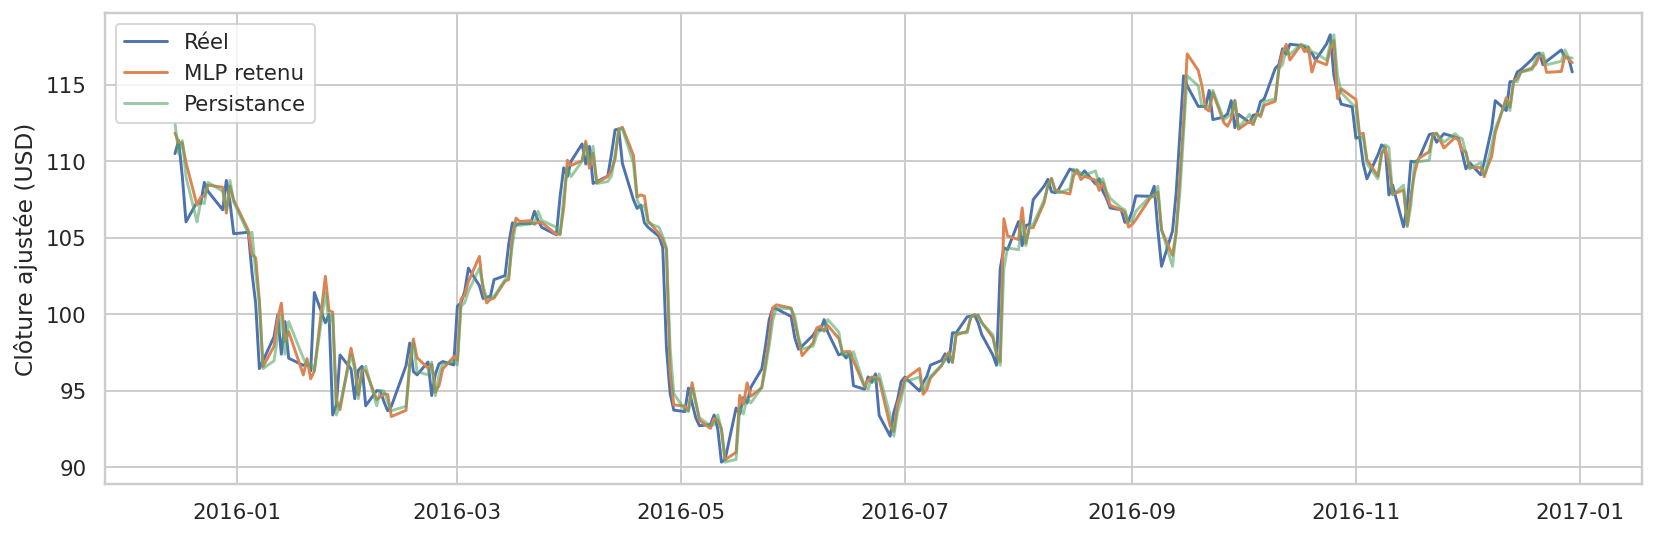

,date,real,mlp,persistence
0,2015-12-15,110.489998,111.82653,112.480003
1,2015-12-16,111.339996,111.22073,110.489998
2,2015-12-17,108.980003,111.19596,111.339996
3,2015-12-18,106.029999,109.90210,108.980003
4,2015-12-21,107.330002,107.12709,106.029999


In [8]:
display(pd.DataFrame(summary['reference']).T)
display(Image(filename=str(output / 'predictions.png')))
display(pd.read_csv(output / 'predictions.csv').head())

## 6. Bilan à discuter

- Distinguer données d'entraînement, validation et test pour éviter une évaluation optimiste.
- Ajuster les prétraitements dans chaque fold de la recherche d'hyperparamètres.
- Choisir une métrique adaptée et comparer à une référence simple.
- Vérifier l'effet réel des régularisations, sans supposer qu'elles améliorent tout.
- Relier les conclusions aux effectifs et aux limites du jeu de données.

Le README rassemble les résultats mesurés et les limites. La synthèse personnelle
de l'étudiant doit être reformulée à partir de ce qu'il a compris et expérimenté.